# Лабораторна робота № 8
## Методи кластеризації та класифікації: Iris, K-Means, PCA

**Мета:** дослідити кластеризацію Iris та студентських даних, порівняти три класифікатори й застосувати PCA.

**Підхід:** Порівняння моделей за компактними таблицями та повторно використовуваними функціями. Висновки друкуються за реально отриманими показниками. Для отримання всіх графіків запустіть комірки зверху вниз у Colab із доступом до інтернету.



### Підготовка бібліотек
Для зовнішнього набору використовується відкритий KaggleHub; за наявності CSV у робочій папці його можна використати замість завантаження.

In [1]:
%pip -q install kagglehub kneed yellowbrick

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from kneed import KneeLocator
from yellowbrick.cluster import KElbowVisualizer

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
PALETTE = 'plasma'
LINE_COLOR = '#a32ea8'
CENTER_COLOR = '#ffb000'
print('Бібліотеки імпортовано. Стиль:', 'seaborn-v0_8-whitegrid')


Бібліотеки імпортовано. Стиль: seaborn-v0_8-whitegrid


## Завдання 1. Кластеризація Iris
**1.1–1.2.** Підготуємо імпорти та завантажимо Iris; для кластеризації використаємо **перші три** числові ознаки з масштабуванням.

In [3]:
iris_dataset = load_iris(as_frame=True)
measurements = iris_dataset.data
selected_iris = measurements.loc[:, measurements.columns[:3]].copy()
iris_scaled = StandardScaler().fit_transform(selected_iris)
display(measurements.head())
print('Відібрані змінні:', ', '.join(selected_iris.columns))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Відібрані змінні: sepal length (cm), sepal width (cm), petal length (cm)


**1.3–1.4.** Складемо таблицю двох критеріїв і візуалізуємо лініями з різними маркерами.

,k,wcss,silhouette
0,1,450.0000,NaN
1,2,190.4685,0.5525
2,3,119.1390,0.4594
3,4,94.6410,0.4057
4,5,75.6278,0.3755
5,6,62.8703,0.3772
6,7,54.2824,0.3628
7,8,46.3125,0.3814
8,9,39.8904,0.3749
9,10,35.2257,0.3791


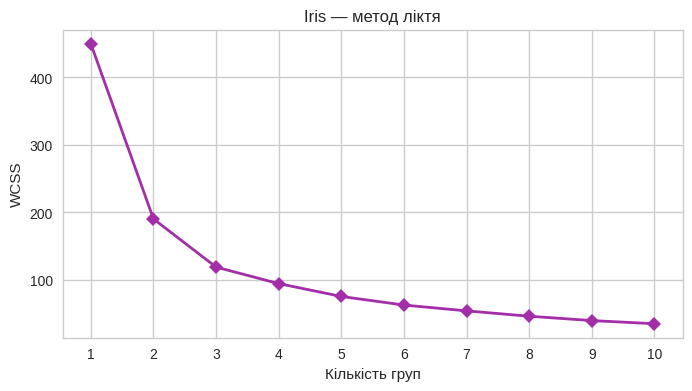

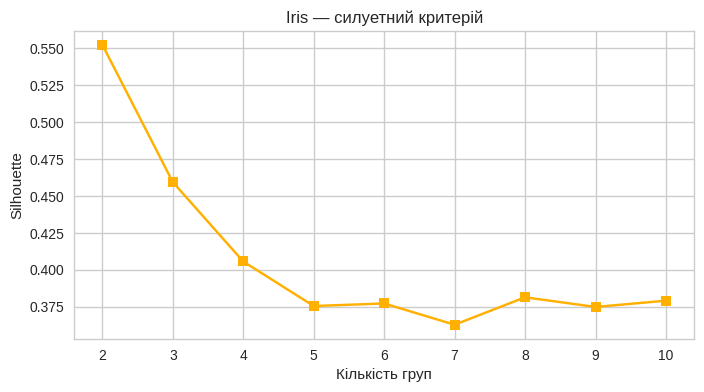

Найкраще за силуетом K: 2


In [4]:
def fit_cluster_metrics(values, k):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(values)
    return (km.inertia_, silhouette_score(values, labels) if k >= 2 else np.nan)

iris_metrics = (
    pd.DataFrame([{'k': k, 'wcss': fit_cluster_metrics(iris_scaled, k)[0]
        } for k in range(1, 11)])
)
iris_metrics['silhouette'] = np.nan

for k in range(2, 11):
    iris_metrics.loc[iris_metrics['k'] == k, 'silhouette'] = fit_cluster_metrics(
        iris_scaled, k)[1]

display(iris_metrics.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(iris_metrics['k'], iris_metrics['wcss'], marker='D', linewidth=2,
    color=LINE_COLOR)
ax.set(title='Iris — метод ліктя', xlabel='Кількість груп', ylabel='WCSS', xticks=range(
    1, 11))
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(iris_metrics['k'][1:], iris_metrics['silhouette'][1:], marker='s',
    color=CENTER_COLOR)
ax.set(title='Iris — силуетний критерій', xlabel='Кількість груп', ylabel='Silhouette',
    xticks=range(2, 11))
plt.show()
best_iris_k = int(iris_metrics.loc[iris_metrics.silhouette.idxmax(), 'k'])
print('Найкраще за силуетом K:', best_iris_k)


In [5]:
iris_elbow = (
    KneeLocator(np.arange(1, 11), iris_metrics['wcss'].to_numpy(), curve='convex',
        direction='decreasing').knee
)
print('Метод ліктя для Iris (WCSS):', iris_elbow if iris_elbow is not None
    else 'немає чіткої точки')


Метод ліктя для Iris (WCSS): 3


**1.5.** Фінальна модель **K-Means з двома кластерами** навчається за трьома ознаками. На графіку показано лише перші дві координати та проєкції центрів.

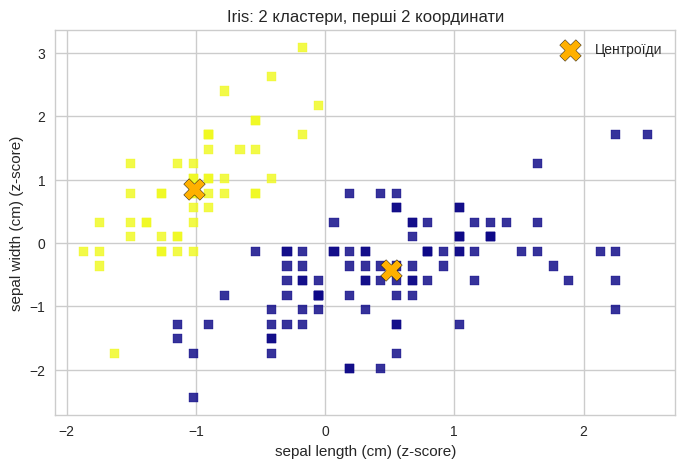

Кількість у двох кластерах: [100, 50]


In [6]:
iris_final = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE)
iris_groups = iris_final.fit_predict(iris_scaled)
fig, ax = plt.subplots(figsize=(8, 5))
plotted = (
    ax.scatter(iris_scaled[:, 0], iris_scaled[:, 1], c=iris_groups, cmap=PALETTE,
        marker='s', s=43, alpha=0.83)
)
ax.scatter(iris_final.cluster_centers_[:, 0], iris_final.cluster_centers_[:, 1], s=240,
    c=CENTER_COLOR, marker='X', edgecolor='black', label='Центроїди')
ax.set(xlabel=selected_iris.columns[0] + ' (z-score)', ylabel=selected_iris.columns[1]
    + ' (z-score)', title='Iris: 2 кластери, перші 2 координати')
ax.legend()
plt.show()
print('Кількість у двох кластерах:', np.bincount(iris_groups).tolist())


## Завдання 2. Дані про успішність студентів
**2.1–2.2.** Завантажимо `rabieelkharoua/students-performance-dataset` із Kaggle або відкриємо локальний CSV. Встановимо імпорти, потрібні для класифікації та кластеризації.

In [7]:
from glob import glob

local_paths = [
    f
    for pattern in (
        'Student_data.csv',
        'Student_performance_data*.csv',
        '/content/Student_data.csv',
        '/content/Student_performance_data*.csv',
    )
    for f in glob(pattern)
]

if local_paths:
    student_csv = local_paths[0]
    print('Локальний файл:', student_csv)
else:
    import kagglehub
    dataset_dir = kagglehub.dataset_download(
        'rabieelkharoua/students-performance-dataset')
    csv_files = sorted(Path(dataset_dir).rglob('*.csv'))
    if not csv_files:
        raise FileNotFoundError('Не знайдено CSV у каталозі KaggleHub')
    student_csv = csv_files[0]
    print('Дані KaggleHub:', student_csv)

students = pd.read_csv(student_csv)
needed = {'StudentID', 'GradeClass', 'Age', 'StudyTimeWeekly', 'Absences', 'GPA'}
assert needed.issubset(students.columns), 'У CSV відсутні необхідні стовпці'
print('Розмір:', students.shape)


Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Дані KaggleHub: /kaggle/input/students-performance-dataset/Student_performance_data _.csv
Розмір: (2392, 15)


**2.3–2.8.** Первинний аналіз: приклади записів, назви й типи стовпців, пропуски, дублікати, статистики.

In [8]:
display(students.head())
print('Стовпці:', students.columns.tolist())
print('Типи даних:')
students.info()
print('\nПропуски:')
print(students.isna().sum().to_string())
print('\nКількість дублікатів:', students.duplicated().sum())
display(students.describe().T.round(2))


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Стовпці: ['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
Типи даних:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64 

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.50,690.66,1001.0,1598.75,2196.50,2794.25,3392.00
Age,2392.0,16.47,1.12,15.0,15.00,16.00,17.00,18.00
Gender,2392.0,0.51,0.50,0.0,0.00,1.00,1.00,1.00
Ethnicity,2392.0,0.88,1.03,0.0,0.00,0.00,2.00,3.00
ParentalEducation,2392.0,1.75,1.00,0.0,1.00,2.00,2.00,4.00
StudyTimeWeekly,2392.0,9.77,5.65,0.0,5.04,9.71,14.41,19.98
Absences,2392.0,14.54,8.47,0.0,7.00,15.00,22.00,29.00
Tutoring,2392.0,0.30,0.46,0.0,0.00,0.00,1.00,1.00
ParentalSupport,2392.0,2.12,1.12,0.0,1.00,2.00,3.00,4.00
Extracurricular,2392.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00


**2.9.** Ціль `GradeClass`; службовий `StudentID` виключаємо. Розбиття 80/20 зі `random_state=42` та стратифікацією. Масштабування для LR/SVM — **всередині Pipeline**, щоб не підглядати в CV-валідацію.

In [9]:
features = students.drop(columns=['StudentID', 'GradeClass'])
target = students['GradeClass']
X_train, X_test, y_train, y_test = (
    train_test_split(features, target, test_size=0.2, random_state=RANDOM_STATE,
        stratify=target)
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('Навчальні:', X_train.shape, 'Тестові:', X_test.shape)
print('Цільова змінна:', target.value_counts().sort_index().to_dict())


Навчальні: (1913, 13) Тестові: (479, 13)
Цільова змінна: {0.0: 107, 1.0: 269, 2.0: 391, 3.0: 414, 4.0: 1211}


**2.10–2.12.** Три класифікатори в одному порівнюваному експерименті: RF, LR та SVM з різними сітками параметрів.

In [10]:
experiments = {
    'Random Forest': (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {
            'n_estimators': [80, 160],
            'max_features': ['sqrt', 0.7],
            'min_samples_split': [2, 6],
        },
    ),
    'Logistic Regression': (
        Pipeline(
            [
                ('normalize', StandardScaler()),
                (
                    'classifier',
                    LogisticRegression(max_iter=2000, solver='lbfgs'),
                ),
            ]
        ),
        {
            'classifier__C': [0.2, 2.0],
            'classifier__class_weight': [None, 'balanced'],
        },
    ),
    'SVM': (
        Pipeline(
            [
                ('normalize', StandardScaler()),
                ('classifier', SVC()),
            ]
        ),
        {
            'classifier__C': [1.0, 4.0],
            'classifier__kernel': ['rbf', 'linear'],
        },
    ),
}

searches = {}

for label, (model, grid) in experiments.items():
    tuned = GridSearchCV(model, grid, cv=folds, scoring='accuracy', n_jobs=-1)
    tuned.fit(X_train, y_train)
    searches[label] = tuned
    print(f'{label}: CV={tuned.best_score_:.4f}; параметри={tuned.best_params_}')

rf_search, lr_search, svm_search = (searches[name] for name in ('Random Forest',
    'Logistic Regression', 'SVM'))


Random Forest: CV=0.9289; параметри={'max_features': 0.7, 'min_samples_split': 6, 'n_estimators': 80}
Logistic Regression: CV=0.7888; параметри={'classifier__C': 2.0, 'classifier__class_weight': None}
SVM: CV=0.8531; параметри={'classifier__C': 4.0, 'classifier__kernel': 'linear'}


**2.13.** Порівняння на тестовій вибірці. Модель для `classification_report` визначається **лише за CV accuracy**, а не за тестом.

In [11]:
model_pairs = [('Random Forest', rf_search), ('Logistic Regression', lr_search), ('SVM',
    svm_search)]
benchmark = (
    pd.DataFrame([{'Модель': name, 'CV accuracy': search.best_score_,
        'Test accuracy': accuracy_score(y_test, search.predict(X_test))} for name,
        search in model_pairs])
)
display(benchmark.round(4).sort_values('CV accuracy', ascending=False))
winner_name, winner_search = max(model_pairs, key=lambda pair: pair[1].best_score_)
print('Найкраща за CV:', winner_name)
print(classification_report(y_test, winner_search.predict(X_test), zero_division=0))


,Модель,CV accuracy,Test accuracy
0,Random Forest,0.9289,0.9248
2,SVM,0.8531,0.8559
1,Logistic Regression,0.7888,0.7933


Найкраща за CV: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.52      0.69        21
         1.0       0.91      0.89      0.90        54
         2.0       0.91      0.95      0.93        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.92       479
   macro avg       0.93      0.84      0.87       479
weighted avg       0.93      0.92      0.92       479



**2.14–2.15.** Для **чотирьох** ознак `Age`, `StudyTimeWeekly`, `Absences`, `GPA` стандартизуємо дані й порівняємо WCSS (K=1…10) та силуети (K=2…10). Мітки `GradeClass` при кластеризації не використовуємо.

In [12]:
study_columns = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
student_matrix = StandardScaler().fit_transform(students[study_columns])
student_k = np.arange(1, 11)
student_inertia, student_sil = ([], [])

for n in student_k:
    km = KMeans(n_clusters=n, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(student_matrix)
    student_inertia.append(km.inertia_)
    if n >= 2:
        student_sil.append(silhouette_score(student_matrix, labels))

student_best_k = int(np.argmax(student_sil) + 2)
print('Найкраще K за силуетом:', student_best_k)
print('Показник:', round(max(student_sil), 4))


Найкраще K за силуетом: 2
Показник: 0.308


,K,Silhouette
0,2,0.308
1,3,0.270
2,4,0.258
3,5,0.264
4,6,0.269
5,7,0.269
6,8,0.271
7,9,0.273
8,10,0.272


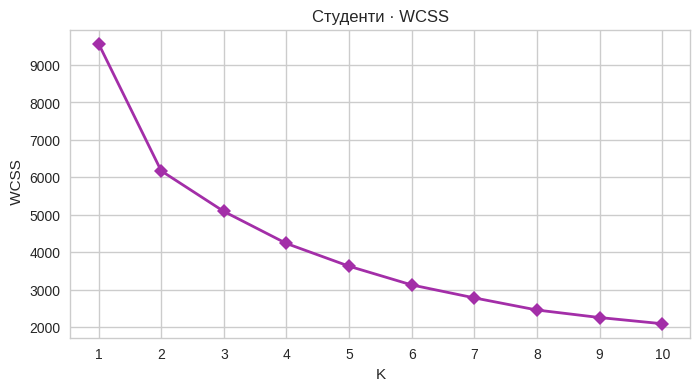

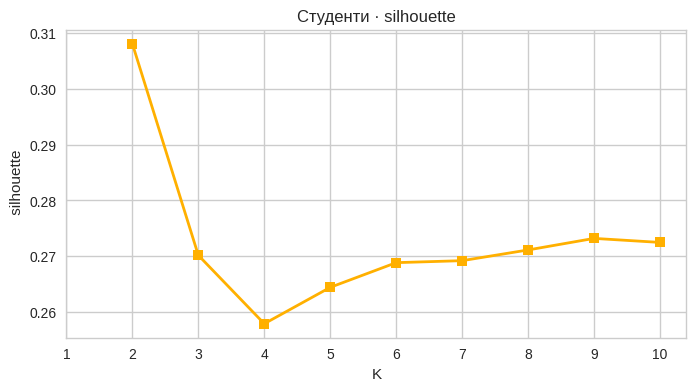

In [13]:
student_metrics = pd.DataFrame({'K': np.arange(2, 11), 'Silhouette': student_sil})
display(student_metrics.round(3))

for title, x, y, marker, color in [
    ('Студенти · WCSS', student_k, student_inertia, 'D', LINE_COLOR),
    ('Студенти · silhouette', range(2, 11), student_sil, 's', CENTER_COLOR),
]:
    plt.figure(figsize=(8, 4))
    plt.plot(x, y, marker=marker, linewidth=2, color=color)
    plt.title(title)
    plt.xticks(range(1, 11))
    plt.xlabel('K')
    plt.ylabel(title.split('·')[1])
    plt.show()


In [14]:
student_elbow = (
    KneeLocator(student_k, student_inertia, curve='convex', direction='decreasing').knee
)
print('Метод ліктя для 4 ознак студентів:', student_elbow if student_elbow is not None
    else 'немає чіткого зламу')


Метод ліктя для 4 ознак студентів: 4


**2.16. PCA та автоматичний пошук ліктя.** У PCA передаємо **всі ознаки, крім `StudentID` і `GradeClass`**. Будуємо частку поясненої дисперсії, пробуємо `KneeLocator`, кумулятивну криву; якщо точку ліктя не знайдено — беремо кількість компонент, що пояснює не менше 90% дисперсії. Кластеризуємо **саме PCA-представлення** у `KElbowVisualizer`.

In [15]:
all_student_features = students.drop(columns=['StudentID', 'GradeClass'])
scaled_all = StandardScaler().fit_transform(all_student_features)
full_pca = PCA().fit(scaled_all)
variance_ratio = full_pca.explained_variance_ratio_
components_axis = np.arange(1, len(variance_ratio) + 1)
cumulative = np.cumsum(variance_ratio)
knee_obj = (
    KneeLocator(components_axis, variance_ratio, curve='convex', direction='decreasing')
)
knee_point = knee_obj.knee
n_components = (
    int(knee_point) if knee_point is not None else int(np.searchsorted(cumulative, 0.9)
        + 1)
)
print('Частки дисперсії:', np.round(variance_ratio, 4))
print('KneeLocator:', knee_point, '| Обрано компонент:', n_components)
print('Кумулятивна частка:', round(float(cumulative[n_components - 1]), 4))
assert 1 <= n_components <= len(variance_ratio)
pcs = PCA(n_components=n_components).fit_transform(scaled_all)


Частки дисперсії: [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]
KneeLocator: 2 | Обрано компонент: 2
Кумулятивна частка: 0.2386


,Компонента,Частка,Накопичено
0,1,0.1525,0.1525
1,2,0.0861,0.2386
2,3,0.0827,0.3213
3,4,0.0807,0.4020
4,5,0.0786,0.4806
5,6,0.0779,0.5586
6,7,0.0763,0.6349
7,8,0.0760,0.7109
8,9,0.0744,0.7853
9,10,0.0738,0.8591


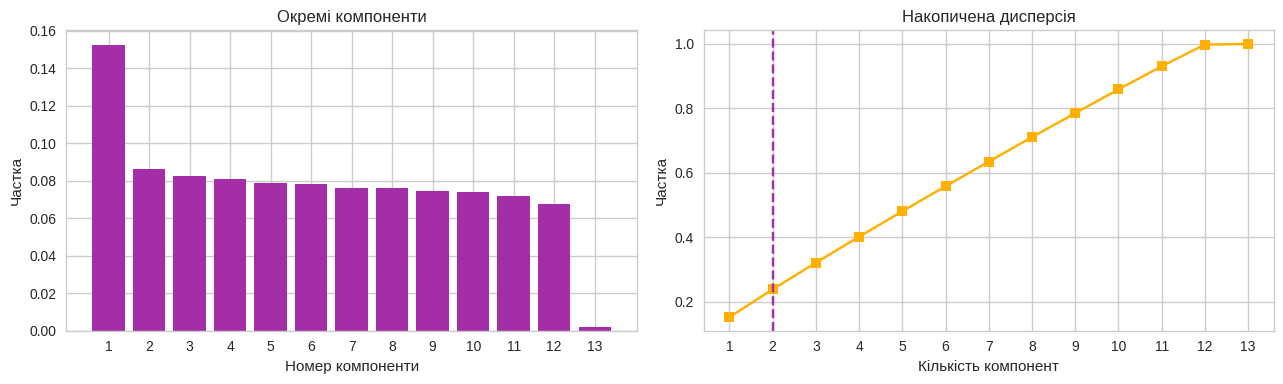

In [16]:
pca_information = (
    pd.DataFrame({'Компонента': components_axis, 'Частка': variance_ratio,
        'Накопичено': cumulative})
)
display(pca_information.round(4))
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].bar(components_axis, variance_ratio, color=LINE_COLOR)
axs[0].set(title='Окремі компоненти', xlabel='Номер компоненти', ylabel='Частка')
axs[1].plot(components_axis, cumulative, 's-', color=CENTER_COLOR)
axs[1].axvline(n_components, ls='--', color=LINE_COLOR)
axs[1].set(title='Накопичена дисперсія', xlabel='Кількість компонент', ylabel='Частка')

for ax in axs:
    ax.set_xticks(components_axis)

plt.tight_layout()
plt.show()


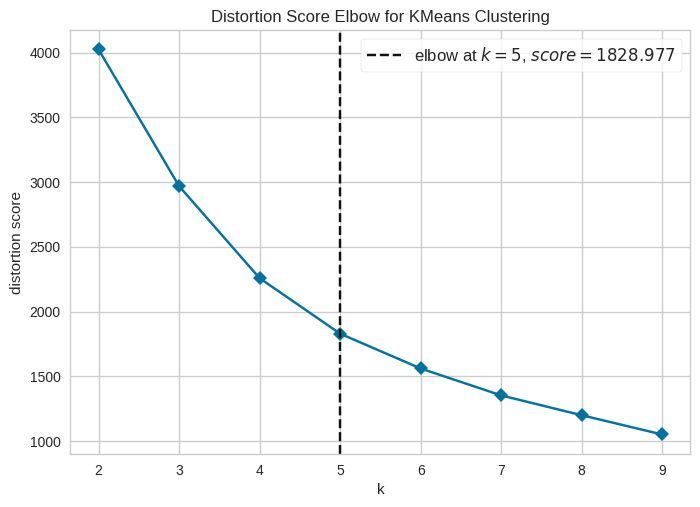

Кластери після PCA за KElbowVisualizer: 5


In [17]:
elbow_pca = (
    KElbowVisualizer(KMeans(n_init=10, random_state=RANDOM_STATE), k=(2, 10),
        timings=False)
)
elbow_pca.fit(pcs)
elbow_pca.show()
print('Кластери після PCA за KElbowVisualizer:', elbow_pca.elbow_value_)


## Висновки


In [20]:
print("Висновки")
print(f"Для Iris оптимальна кількість кластерів: {best_iris_k}.")
print(f"Найкращий класифікатор — {winner_name}.")
print(f"Точність CV: {winner_search.best_score_:.3f}.")
print(f"PCA зберіг {cumulative[n_components-1]:.1%} дисперсії.")
print("Методи дозволили порівняти різні способи аналізу даних.")

Висновки
Для Iris оптимальна кількість кластерів: 2.
Найкращий класифікатор — Random Forest.
Точність CV: 0.929.
PCA зберіг 23.9% дисперсії.
Методи дозволили порівняти різні способи аналізу даних.
